# Customer Segmentation (CIRP)

# Importing necessary libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

Paths and settings

In [2]:
DATA_PATH = '../data/segmentation/customer_level_segmentation.csv'
SAMPLE_PATH = '../data/samples/sample_customers.csv'
MODEL_PATH = '../models/segmentation/segmentation_model.joblib'
FIG_PATH = '../reports/figures/'
RANDOM = 42
N_INIT = 50   # number of random starts for K-Means (more starts = more stable result)

# Data Loading and Inspection

Load the customer-level data (one row per customer)

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,Customer ID,recency,frequency,monetary,avg_order_value,std_order_value,tenure,avg_days_between_orders,std_days_between_orders,recency_to_gap_ratio,...,return_rate,orders_last_30d,orders_last_60d,orders_last_90d,spend_last_90d,spend_trend,frequency_trend,is_uk,weekend_share,churn_profiling_only
0,12346,233.582639,3,77352.96,25784.320,44513.119522,555.452778,160.935069,60.675163,1.451409,...,0.997811,0.0,0.0,0.0,0.00,0.00000,0.000000,1,0.000000,1
1,12347,37.633333,6,3402.39,567.065,118.733848,312.402778,54.953889,12.905019,0.684817,...,0.000000,0.0,1.0,1.0,584.91,-0.27054,-0.333333,0,0.243902,0
2,12348,156.550694,4,1388.40,347.100,212.295941,346.375694,63.275000,21.084052,2.474132,...,0.000000,0.0,0.0,0.0,0.00,-1.00000,-1.000000,0,0.000000,0
3,12349,315.650694,2,2221.14,1110.570,59.467680,497.444444,181.793750,0.000000,1.736312,...,0.010873,0.0,0.0,0.0,0.00,0.00000,0.000000,0,0.000000,0
4,12350,218.332639,1,294.40,294.400,0.000000,218.332639,67.317361,0.000000,3.243333,...,0.000000,0.0,0.0,0.0,0.00,0.00000,0.000000,0,0.000000,1


Display summary information

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5253 entries, 0 to 5252
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer ID              5253 non-null   int64  
 1   recency                  5253 non-null   float64
 2   frequency                5253 non-null   int64  
 3   monetary                 5253 non-null   float64
 4   avg_order_value          5253 non-null   float64
 5   std_order_value          5253 non-null   float64
 6   tenure                   5253 non-null   float64
 7   avg_days_between_orders  5253 non-null   float64
 8   std_days_between_orders  5253 non-null   float64
 9   recency_to_gap_ratio     5253 non-null   float64
 10  is_single_order          5253 non-null   int64  
 11  n_unique_products        5253 non-null   int64  
 12  avg_basket_size          5253 non-null   float64
 13  avg_unit_price           5253 non-null   float64
 14  return_rate              5253 non-n

Show statistical summary

In [5]:
df.describe()

,Customer ID,recency,frequency,monetary,avg_order_value,std_order_value,tenure,avg_days_between_orders,std_days_between_orders,recency_to_gap_ratio,...,return_rate,orders_last_30d,orders_last_60d,orders_last_90d,spend_last_90d,spend_trend,frequency_trend,is_uk,weekend_share,churn_profiling_only
count,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,...,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000,5253.000000
mean,15329.438416,206.144124,5.703788,2601.554967,370.032360,152.930109,430.367267,83.591922,30.918748,8.932519,...,0.023447,0.250904,0.502951,0.739577,343.560584,-0.027270,-0.021756,0.913002,0.146041,0.566343
std,1711.679592,173.925191,11.202178,12095.864128,638.200817,757.805885,180.446211,68.893288,45.273640,45.820758,...,0.083139,0.714781,1.257817,1.772137,1941.251738,0.584355,0.578209,0.281859,0.280234,0.495626
min,12346.000000,0.168056,1.000000,1.550000,1.550000,0.000000,0.509722,0.000694,0.000000,0.001954,...,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000
25%,13856.000000,49.319444,1.000000,317.000000,174.190000,0.000000,309.663889,49.507465,0.000000,0.648691,...,0.000000,0.000000,0.000000,0.000000,0.000000,-0.129403,0.000000,1.000000,0.000000,0.000000
50%,15321.000000,162.548611,3.000000,776.660000,275.259000,71.382430,472.480556,67.317361,9.476423,2.099910,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
75%,16813.000000,323.581250,6.000000,2061.770000,407.933636,167.860079,585.342361,90.597083,48.535456,5.089553,...,0.014790,0.000000,1.000000,1.000000,260.740000,0.000000,0.000000,1.000000,0.158648,1.000000
max,18287.000000,646.549306,284.000000,456780.490000,25784.320000,44513.119522,646.677083,632.120139,440.492660,646.449306,...,1.000000,15.000000,31.000000,45.000000,62151.700000,1.000000,1.000000,1.000000,1.000000,1.000000


Check for missing values and duplicated customers

In [6]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicated customers:', df['Customer ID'].duplicated().sum())

Missing values: 0
Duplicated customers: 0


# Features for Clustering

Select the behavioral features

In [7]:
# churn_profiling_only is NOT used for clustering, only to describe the clusters later
FEATURES = ['recency', 'frequency', 'monetary', 'avg_order_value',
            'avg_days_between_orders', 'n_unique_products',
            'return_rate', 'weekend_share', 'spend_trend']

# skewed columns -> log transform
LOG_COLS = ['frequency', 'monetary', 'avg_order_value',
            'avg_days_between_orders', 'n_unique_products', 'return_rate']

df[FEATURES].skew().sort_values(ascending=False)

monetary                   23.996554
avg_order_value            20.384990
frequency                  10.490706
return_rate                 7.987561
n_unique_products           6.114841
avg_days_between_orders     2.728253
weekend_share               2.078729
recency                     0.671700
spend_trend                 0.031697
dtype: float64

Effect of the log transform (monetary)

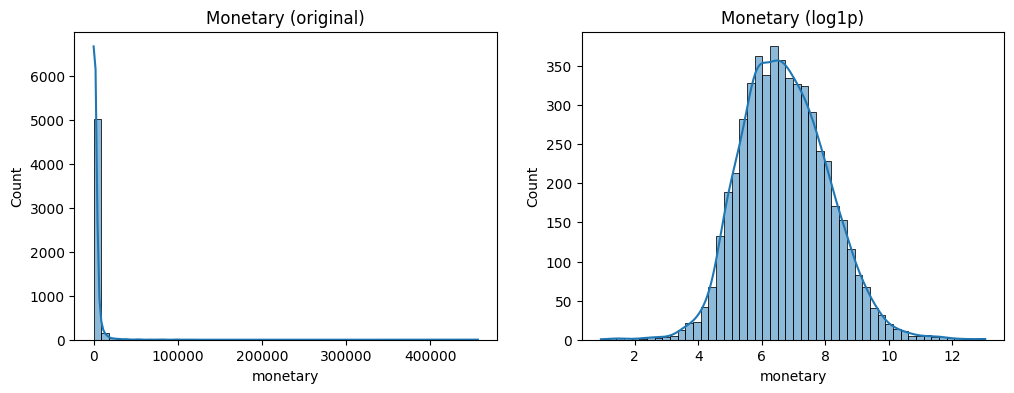

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['monetary'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Monetary (original)')

sns.histplot(np.log1p(df['monetary']), bins=50, kde=True, ax=axes[1])
axes[1].set_title('Monetary (log1p)')

plt.show()

Function: log transform + scaling

In [9]:
def transform(df_raw, scaler=None):
    """log1p on the skewed columns, then StandardScaler. Returns (X_scaled, scaler)."""
    X = df_raw[FEATURES].copy()
    X[LOG_COLS] = np.log1p(X[LOG_COLS])
    if scaler is None:
        scaler = StandardScaler().fit(X)
    return scaler.transform(X), scaler

Apply the transformation

In [10]:
X, scaler = transform(df)

# after scaling: mean = 0 and std = 1 for every feature
pd.DataFrame(X, columns=FEATURES).describe().loc[['mean', 'std']].round(2)

,recency,frequency,monetary,avg_order_value,avg_days_between_orders,n_unique_products,return_rate,weekend_share,spend_trend
mean,-0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


# Choosing the Number of Clusters (K-Means)

Elbow, Silhouette and Davies-Bouldin for k = 2 to 10

In [11]:
results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM).fit(X)
    results.append({'k': k,
                    'inertia': model.inertia_,
                    'silhouette': silhouette_score(X, model.labels_),
                    'davies_bouldin': davies_bouldin_score(X, model.labels_)})

k_results = pd.DataFrame(results)
k_results.round(3)

,k,inertia,silhouette,davies_bouldin
0,2,36380.130,0.224,1.625
1,3,32566.445,0.236,1.507
2,4,29204.412,0.244,1.321
3,5,25933.521,0.192,1.471
4,6,23168.517,0.217,1.350
5,7,21420.731,0.214,1.340
6,8,19845.937,0.222,1.272
7,9,18858.002,0.201,1.341
8,10,18033.390,0.201,1.343


Plot the three measures

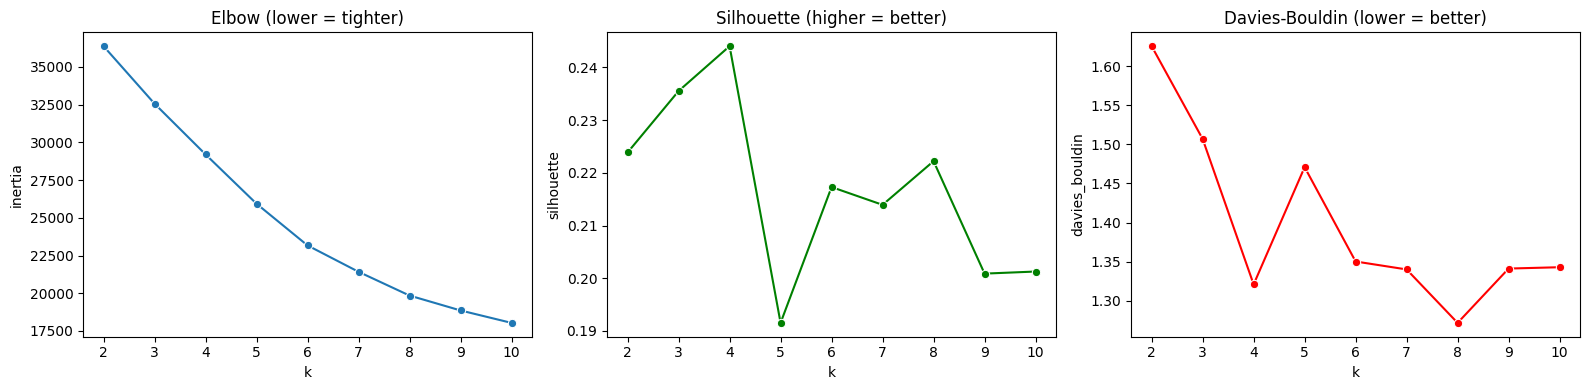

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.lineplot(x='k', y='inertia', data=k_results, marker='o', ax=axes[0])
axes[0].set_title('Elbow (lower = tighter)')

sns.lineplot(x='k', y='silhouette', data=k_results, marker='o', color='green', ax=axes[1])
axes[1].set_title('Silhouette (higher = better)')

sns.lineplot(x='k', y='davies_bouldin', data=k_results, marker='o', color='red', ax=axes[2])
axes[2].set_title('Davies-Bouldin (lower = better)')

plt.tight_layout()
plt.savefig(FIG_PATH + 'seg_01_k_selection.png', bbox_inches='tight')
plt.show()

Choose k

In [13]:
K_FINAL = 6

# k = 4 has the best scores, but it puts all active customers in one big group (about 39%),
#     which is not useful for marketing.
# k = 5 is worse than k = 4 and k = 6 on both Silhouette and Davies-Bouldin.
# k = 6 separates loyal customers from rising customers and gives the most useful groups,
#     with good scores and a stable result (see the next check).
# Silhouette is low for every k, because customer behavior changes gradually (no clear gaps).
k_results[k_results['k'].isin([4, 5, 6])].round(3)

,k,inertia,silhouette,davies_bouldin
2,4,29204.412,0.244,1.321
3,5,25933.521,0.192,1.471
4,6,23168.517,0.217,1.350


Stability check: same k with different random starts

In [14]:
# Adjusted Rand Index = 1 means exactly the same clusters
base = KMeans(n_clusters=K_FINAL, n_init=N_INIT, random_state=RANDOM).fit(X).labels_

for seed in [1, 7, 21, 99]:
    other = KMeans(n_clusters=K_FINAL, n_init=N_INIT, random_state=seed).fit(X).labels_
    print('seed', seed, '-> ARI =', round(adjusted_rand_score(base, other), 3))

seed 1 -> ARI = 0.975


seed 7 -> ARI = 0.976


seed 21 -> ARI = 0.989
seed 99 -> ARI = 1.0


# DBSCAN Comparison

Try different eps values (min_samples = 10)

In [15]:
rows = []
for eps in [0.5, 0.8, 1.0, 1.5, 2.0]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = (labels == -1).sum()

    # silhouette needs at least 2 clusters (noise points are excluded)
    if n_clusters >= 2:
        sil = silhouette_score(X[labels != -1], labels[labels != -1])
    else:
        sil = np.nan

    rows.append({'eps': eps, 'clusters': n_clusters, 'noise_points': noise,
                 'noise_%': round(noise / len(X) * 100, 1), 'silhouette': round(sil, 3)})

dbscan_results = pd.DataFrame(rows)
dbscan_results

,eps,clusters,noise_points,noise_%,silhouette
0,0.5,9,4092,77.9,0.342
1,0.8,9,1782,33.9,-0.128
2,1.0,4,950,18.1,0.224
3,1.5,2,245,4.7,0.377
4,2.0,1,106,2.0,NaN


Conclusion

In [16]:
# size of the clusters for two eps values
for eps in [1.0, 1.5]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    print('eps =', eps, '->', pd.Series(labels).value_counts().to_dict(), '(-1 = noise)')

eps = 1.0 -> {0: 4237, -1: 950, 1: 26, 2: 22, 3: 18} (-1 = noise)


eps = 1.5 -> {0: 4968, -1: 245, 1: 40} (-1 = noise)


DBSCAN gives one giant cluster (about 85% to 95% of the customers) with a few tiny clusters and many noise points, because the customers form one continuous cloud and not separated dense groups. Its silhouette for eps = 1.5 looks higher only because noise points are excluded and there is practically one big cluster, so it cannot be used to segment customers. **K-Means is selected** for the platform.

# Final K-Means Model

Fit the final model

In [17]:
km = KMeans(n_clusters=K_FINAL, n_init=N_INIT, random_state=RANDOM).fit(X)
df['cluster'] = km.labels_

print('Silhouette:', round(silhouette_score(X, km.labels_), 3))
print('Davies-Bouldin:', round(davies_bouldin_score(X, km.labels_), 3))
df['cluster'].value_counts().sort_index()

Silhouette: 0.217
Davies-Bouldin: 1.35


cluster
0      77
1     719
2    1590
3    1341
4     488
5    1038
Name: count, dtype: int64

# Cluster Profiles

Profile of each cluster

In [18]:
prof = df.groupby('cluster').agg(
    size=('cluster', 'size'),
    recency=('recency', 'median'),
    frequency=('frequency', 'median'),
    monetary=('monetary', 'median'),
    avg_order_value=('avg_order_value', 'median'),
    avg_days_between_orders=('avg_days_between_orders', 'median'),
    n_unique_products=('n_unique_products', 'median'),
    return_rate=('return_rate', 'mean'),
    weekend_share=('weekend_share', 'mean'),
    spend_trend=('spend_trend', 'mean'),
    churn_rate=('churn_profiling_only', 'mean'))   # churn is used ONLY here

prof['pct_of_customers'] = (prof['size'] / len(df) * 100).round(1)
prof.round(2).T

cluster,0,1,2,3,4,5
size,77.00,719.00,1590.00,1341.00,488.00,1038.00
recency,309.43,37.27,171.65,350.55,298.39,31.43
frequency,2.00,3.00,3.00,1.00,2.00,12.00
monetary,385.19,794.56,1021.20,234.24,398.96,4660.98
avg_order_value,190.48,269.08,318.88,172.80,215.34,370.02
avg_days_between_orders,67.32,83.43,81.53,67.32,67.32,39.14
n_unique_products,12.00,38.00,51.00,14.00,32.00,157.50
return_rate,0.58,0.01,0.02,0.01,0.01,0.02
weekend_share,0.11,0.09,0.06,0.01,0.88,0.14
spend_trend,-0.08,0.93,-0.42,-0.07,-0.03,-0.03


# Naming the Clusters

Rule-based names (they follow the profile, not the cluster number)

In [19]:
def name_clusters(p):
    names = {}
    for c, r in p.iterrows():
        if r.return_rate > 0.3:
            names[c] = 'High Returners'
        elif r.weekend_share > 0.5:
            names[c] = 'Weekend Shoppers (Lapsing)'
        elif r.recency < 100 and r.frequency >= 8:
            names[c] = 'Loyal Champions'
        elif r.recency < 100 and r.spend_trend > 0.3:
            names[c] = 'New / Rising Customers'
        elif r.recency < 100:
            names[c] = 'Active Regulars'
        elif r.frequency <= 1.5:
            names[c] = 'One-Time Lapsed'
        elif r.recency > 250:
            names[c] = 'Fading Customers'
        else:
            names[c] = 'At-Risk Occasionals'

    # two clusters must not have the same name
    seen = {}
    for c, n in names.items():
        seen[n] = seen.get(n, 0) + 1
        if seen[n] > 1:
            names[c] = n + ' ' + str(seen[n])
    return names

NAMES = name_clusters(prof)
prof.insert(0, 'cluster_name', prof.index.map(NAMES))
df['cluster_name'] = df['cluster'].map(NAMES)
NAMES

{0: 'High Returners',
 1: 'New / Rising Customers',
 2: 'At-Risk Occasionals',
 3: 'One-Time Lapsed',
 4: 'Weekend Shoppers (Lapsing)',
 5: 'Loyal Champions'}

# Business Description of the Segments

Description and suggested action for the marketing team

In [20]:
SEGMENT_INFO = {
    'Loyal Champions': ('Buy often and recently, spend the most, buy many different products. Lowest churn.',
                        'Reward them: loyalty benefits, early access to new products, ask for referrals. Avoid unnecessary discounts.'),
    'New / Rising Customers': ('Bought recently and their spending is growing fast.',
                               'Nurture them: welcome series, cross-sell suggestions, encourage the next order.'),
    'Active Regulars': ('Recently active customers with steady spending.',
                        'Keep them engaged: regular newsletters, bundles, seasonal offers.'),
    'At-Risk Occasionals': ('Buy from time to time; the last order was months ago and their spending is going down.',
                            'Act now: reminder emails and a targeted offer before they leave.'),
    'Weekend Shoppers (Lapsing)': ('Buy almost only on weekends and have not ordered for a long time.',
                                   'Win them back with weekend-timed offers and reminders.'),
    'One-Time Lapsed': ('Placed one order a long time ago and never came back; lowest spend.',
                        'Low-cost reactivation (one email or a small first-order-back offer); do not invest heavily.'),
    'High Returners': ('Return a very large share of what they buy; few orders and inactive for a long time.',
                       'Find out why they return (quality, wrong orders); avoid expensive campaigns until this is clear.'),
    'Fading Customers': ('Several orders in the past but inactive for a very long time.',
                         'Strong win-back campaign with a clear incentive.')
}

def get_info(name):
    base = name.rsplit(' ', 1)[0] if name not in SEGMENT_INFO and name[-1].isdigit() else name
    return SEGMENT_INFO.get(base, ('No description yet.', 'Review this segment manually.'))

prof['description'] = [get_info(n)[0] for n in prof['cluster_name']]
prof['suggested_action'] = [get_info(n)[1] for n in prof['cluster_name']]
prof[['cluster_name', 'size', 'pct_of_customers', 'churn_rate', 'description', 'suggested_action']]

,cluster_name,size,pct_of_customers,churn_rate,description,suggested_action
cluster,,,,,,
0,High Returners,77,1.5,0.792208,Return a very large share of what they buy; fe...,"Find out why they return (quality, wrong order..."
1,New / Rising Customers,719,13.7,0.470097,Bought recently and their spending is growing ...,"Nurture them: welcome series, cross-sell sugge..."
2,At-Risk Occasionals,1590,30.3,0.588679,Buy from time to time; the last order was mont...,Act now: reminder emails and a targeted offer ...
3,One-Time Lapsed,1341,25.5,0.829232,Placed one order a long time ago and never cam...,Low-cost reactivation (one email or a small fi...
4,Weekend Shoppers (Lapsing),488,9.3,0.692623,Buy almost only on weekends and have not order...,Win them back with weekend-timed offers and re...
5,Loyal Champions,1038,19.8,0.183044,"Buy often and recently, spend the most, buy ma...","Reward them: loyalty benefits, early access to..."


# Visualizing the Clusters

Clusters in PCA space

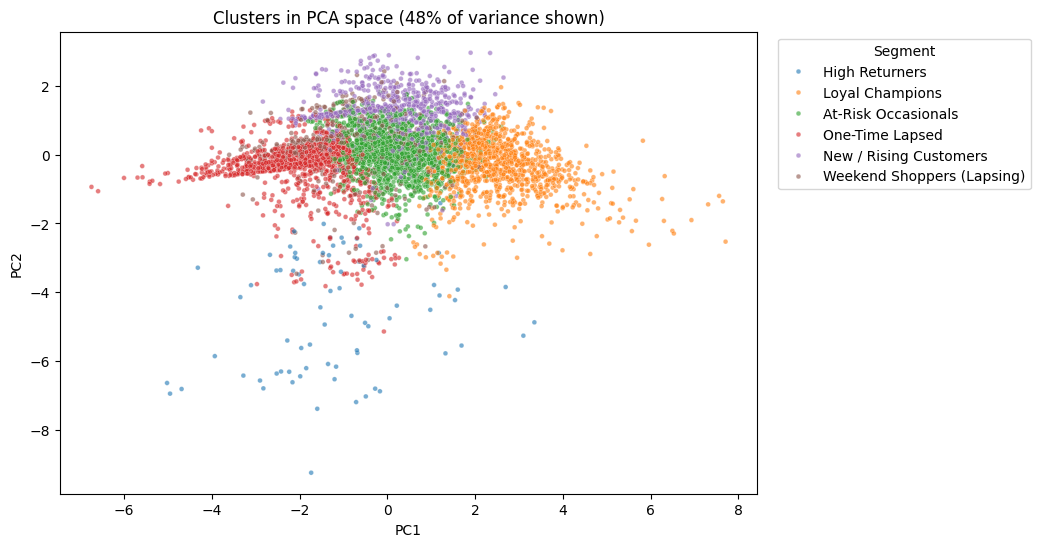

In [21]:
pca = PCA(n_components=2, random_state=RANDOM)
P = pca.fit_transform(X)
df['PC1'] = P[:, 0]
df['PC2'] = P[:, 1]

plt.figure(figsize=(9, 6))
sns.scatterplot(x='PC1', y='PC2', hue='cluster_name', data=df, s=12, alpha=0.6)
plt.title('Clusters in PCA space (' + str(round(pca.explained_variance_ratio_.sum() * 100)) + '% of variance shown)')
plt.legend(title='Segment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig(FIG_PATH + 'seg_02_pca_clusters.png', bbox_inches='tight')
plt.show()

Segment size, churn rate and spending

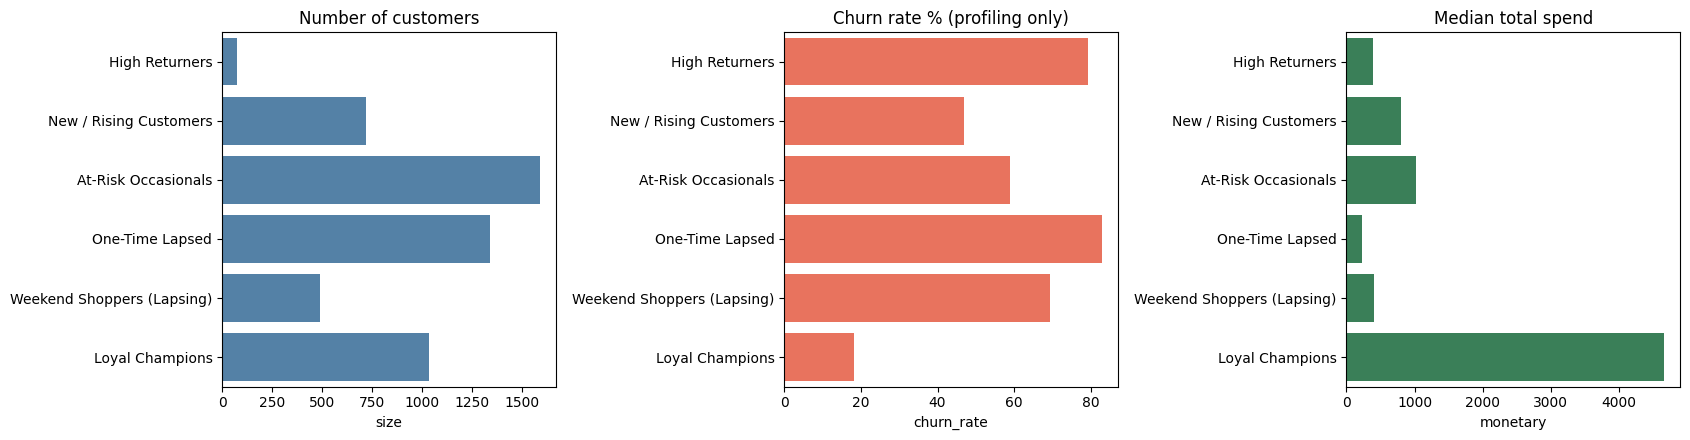

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.barplot(x='size', y='cluster_name', data=prof, color='steelblue', ax=axes[0])
axes[0].set_title('Number of customers')

sns.barplot(x=prof['churn_rate'] * 100, y=prof['cluster_name'], color='tomato', ax=axes[1])
axes[1].set_title('Churn rate % (profiling only)')

sns.barplot(x='monetary', y='cluster_name', data=prof, color='seagreen', ax=axes[2])
axes[2].set_title('Median total spend')

for a in axes:
    a.set_ylabel('')
plt.tight_layout()
plt.savefig(FIG_PATH + 'seg_03_cluster_overview.png', bbox_inches='tight')
plt.show()

Heatmap of the cluster profiles

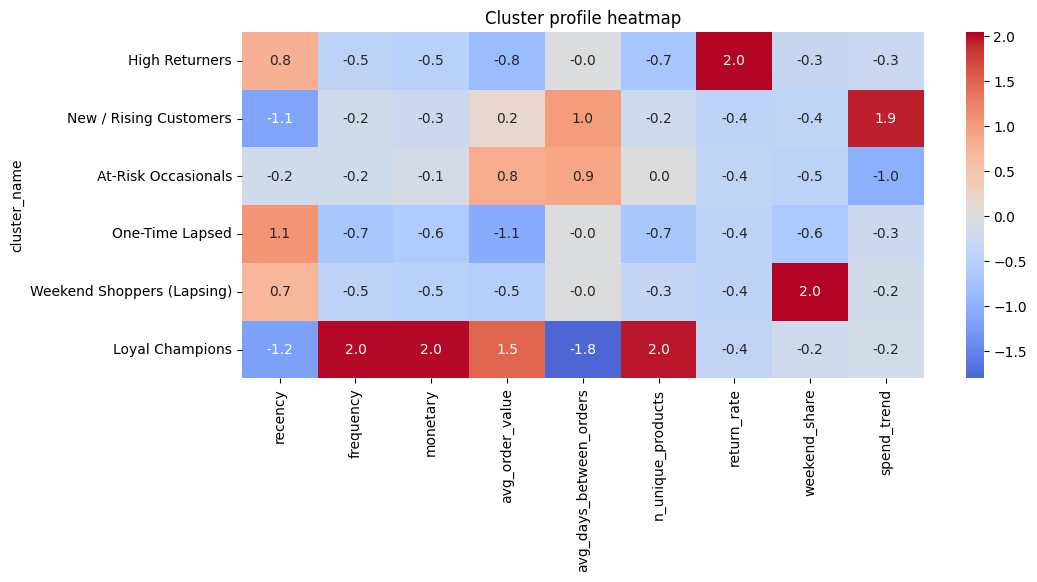

In [23]:
# z-score of each feature across the clusters (red = high, blue = low)
heat = (prof[FEATURES] - prof[FEATURES].mean()) / prof[FEATURES].std()
heat.index = prof['cluster_name']

plt.figure(figsize=(11, 4.5))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Cluster profile heatmap')
plt.savefig(FIG_PATH + 'seg_04_cluster_heatmap.png', bbox_inches='tight')
plt.show()

# Saving the Model and the Files

Save the model, the scaler and the profiles

In [24]:
artifacts = {'kmeans': km, 'scaler': scaler, 'features': FEATURES, 'log_cols': LOG_COLS,
             'cluster_names': NAMES, 'profiles': prof}
joblib.dump(artifacts, MODEL_PATH)

prof.round(3).to_csv('../data/segmentation/cluster_profiles.csv')
df.drop(columns=['PC1', 'PC2']).to_csv('../data/segmentation/customers_with_clusters.csv', index=False)

# Function for the Platform

Predict the segment of a new customer

In [25]:
def load_segmentation_model(path=MODEL_PATH):
    return joblib.load(path)

def predict_segment(customer, art=None):
    """customer = dict with the 9 raw (unscaled) feature values.
    Returns the cluster number, the segment name, a description and an action."""
    if art is None:
        art = load_segmentation_model()

    missing = [f for f in art['features'] if f not in customer]
    if missing:
        raise ValueError('Missing features: ' + str(missing))
    if any(customer[c] < 0 for c in art['log_cols']):
        raise ValueError('Negative values are not allowed in: ' + str(art['log_cols']))

    row = pd.DataFrame([customer])[art['features']]
    Xc, _ = transform(row, art['scaler'])
    c = int(art['kmeans'].predict(Xc)[0])
    p = art['profiles'].loc[c]

    return {'cluster': c,
            'cluster_name': art['cluster_names'][c],
            'description': p['description'],
            'suggested_action': p['suggested_action'],
            'summary': {'customers_in_cluster': int(p['size']),
                        'share_pct': float(p['pct_of_customers']),
                        'typical_recency_days': round(float(p['recency']), 1),
                        'typical_orders': float(p['frequency']),
                        'typical_total_spend': round(float(p['monetary']), 2),
                        'cluster_churn_rate': round(float(p['churn_rate']), 3)}}

Test with the first sample customer

In [26]:
art = load_segmentation_model()
sample = pd.read_csv(SAMPLE_PATH)
predict_segment(sample.iloc[0][FEATURES].to_dict(), art)

{'cluster': 1,
 'cluster_name': 'New / Rising Customers',
 'description': 'Bought recently and their spending is growing fast.',
 'suggested_action': 'Nurture them: welcome series, cross-sell suggestions, encourage the next order.',
 'summary': {'customers_in_cluster': 719,
  'share_pct': 13.7,
  'typical_recency_days': 37.3,
  'typical_orders': 3.0,
  'typical_total_spend': 794.56,
  'cluster_churn_rate': 0.47}}

Test with the 20 sample customers

In [27]:
out = []
for i in range(len(sample)):
    r = predict_segment(sample.iloc[i][FEATURES].to_dict(), art)
    out.append({'Customer ID': sample.iloc[i]['Customer ID'], 'cluster': r['cluster'], 'segment': r['cluster_name']})
pd.DataFrame(out)

,Customer ID,cluster,segment
0,12358.0,1,New / Rising Customers
1,16212.0,2,At-Risk Occasionals
2,16226.0,2,At-Risk Occasionals
3,17497.0,4,Weekend Shoppers (Lapsing)
4,13524.0,1,New / Rising Customers
5,16806.0,2,At-Risk Occasionals
6,18154.0,3,One-Time Lapsed
7,17518.0,4,Weekend Shoppers (Lapsing)
8,17470.0,5,Loyal Champions
9,17201.0,2,At-Risk Occasionals


Check: the function gives the same clusters as the training

In [28]:
labels_again = [predict_segment(df.iloc[i][FEATURES].to_dict(), art)['cluster'] for i in range(len(df))]
print('Same cluster for', round((np.array(labels_again) == df['cluster'].values).mean() * 100, 1), '% of the customers')

Same cluster for 100.0 % of the customers


# Summary of Analysis

*   **Data**: 5,253 customers, 9 behavioral features, no missing values. Skewed features were log-transformed and scaled.
*   **Number of clusters**: k = 6 was chosen (Silhouette 0.22, Davies-Bouldin 1.35). Silhouette is low for all k because customer behavior is continuous. With 50 random starts the clusters are stable (ARI above 0.97).
*   **DBSCAN**: gave one giant cluster plus noise, so K-Means was selected.
*   **Segments**: each cluster has a name, a description and a suggested action. One segment (High Returners) is small (about 1.5%) but clearly different from the others. Churn rate was used only to describe the segments.
*   **Platform**: `predict_segment()` returns the segment of a new customer and is ready for the Streamlit app.